# Notebook 03: AI Socket Designer
Notebook 03 builds the AI that designs socket for the residual limb. It covers the following:
1. Simulator rebuilt in PyTorch
2. Expert optimizer to design best volume socket for any patient
3. AI designer which learns from expert and physics methods
4. Comparison between designs
5. Final AI draft + quick polish

**Before you start:** Notebooks 01 and 02 need to be ran with 200 patients.

Change GPU to T4. **Runtime > Change runtime type > T4 GPU > Save**


## Setup

In [3]:
import os, time
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/all-day-socket/data'
except ImportError:
    OUT_DIR = 'data'

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on:', DEV)
torch.manual_seed(0); np.random.seed(0)

Mounted at /content/drive
Running on: cuda


## Load the grids from Notebook 02


In [4]:
G = dict(np.load(f'{OUT_DIR}/socket_grids_v1.npz'))
E_TISSUE, MU, LOAD_N, T_MIN, BONY_MM = [float(x) for x in G['settings']]
NP, NV, H, W = G['T'].shape
N_EXT = G['R_ext'].shape[2]
REF = int(G['ref_index'])
GROUPS = G['groups']
VOLUME_CHANGES = list(G['volume_changes'])
print(f'E = {E_TISSUE} kPa | MU = {MU} | load = {LOAD_N} N | {NP} patients x {NV} volumes')

empty = np.where(G['bony'].reshape(NP, -1).sum(1) == 0)[0]
assert len(empty) == 0, f'Patients {empty.tolist()} have no bony zone: update zone_masks in Notebook 02 and rerun Step 12.'

def gpu(a, dtype=torch.float32):
    return torch.tensor(np.asarray(a), dtype=dtype, device=DEV)

R_REF, R_EXT, Z_ = gpu(G['R_ref']), gpu(G['R_ext']), gpu(G['Z'])
Z0, DZE, T_ = gpu(G['z_ext0']), gpu(G['dz_ext']), gpu(G['T'])
BONY, PT = gpu(G['bony'], torch.bool), gpu(G['pt'], torch.bool)
PTB = gpu(G['ptb'])
BZ, BTH = gpu(G['BZ']), gpu(G['BTH'])
NK_Z, NK_TH = BZ.shape[1], BTH.shape[1]
KNOB_LIMIT = 8.0
IDS = {g: np.where(GROUPS == g)[0] for g in ['train', 'val', 'test']}
print({g: len(v) for g, v in IDS.items()})

E = 40.0 kPa | MU = 0.75 | load = 400.0 N | 200 patients x 5 volumes
{'train': 140, 'val': 30, 'test': 30}


## PyTorch Simulator
Same as notebook 02 simulator but runs in batches with gradients


In [6]:
VIDX = torch.arange(NV, device=DEV)

def limb_at(p, v, ds):
    idx = ((Z_[p] + ds[:, None] - Z0[p, v][:, None]) / DZE[p, v][:, None]).clamp(0, N_EXT - 1.001)
    i0 = idx.floor().long()
    fr = (idx - i0)[..., None]
    R = R_EXT[p, v]
    take = lambda i: torch.gather(R, 1, i[..., None].expand(-1, -1, W))
    return take(i0) * (1 - fr) + take(i0 + 1) * fr

def simulate(p, v, offset, mu=MU, E=E_TISSUE, load=LOAD_N):
    S = R_REF[p] + offset                                   # socket radius
    k = E / T_[p, v].clamp(min=T_MIN)                       # spring stiffness
    dz = (Z_[p][:, 1] - Z_[p][:, 0])[:, None, None]
    taper = torch.empty_like(S)                             # same as np.gradient along height
    taper[:, 1:-1] = (S[:, 2:] - S[:, :-2]) / (2 * dz)
    taper[:, 0] = (S[:, 1] - S[:, 0]) / dz[:, 0]
    taper[:, -1] = (S[:, -1] - S[:, -2]) / dz[:, 0]
    lift = S * (taper + mu * torch.sqrt(1 + taper ** 2)) * (2 * np.pi / W) * dz.abs() * 1e-3

    def force(ds):
        P = k * (limb_at(p, v, ds) - S).clamp(min=0)
        return (P * lift).sum((1, 2)), P

    with torch.no_grad():
        lo = torch.full((len(p),), -30.0, device=DEV)
        hi = torch.full((len(p),), 80.0, device=DEV)
        for _ in range(40):
            mid = 0.5 * (lo + hi)
            too_low = force(mid)[0] < load
            lo, hi = torch.where(too_low, mid, lo), torch.where(too_low, hi, mid)
        sink0 = 0.5 * (lo + hi)
        dF = (force(sink0 + 0.01)[0] - force(sink0 - 0.01)[0]) / 0.02
    sink = sink0 - (force(sink0)[0] - load) / dF  # same value but with gradients
    F_, P = force(sink)
    return P, sink, (F_.detach() - load).abs() < 1.0

def knobs_to_offset(knobs):
    return BZ @ knobs @ BTH.T

### Compare to Notebook 02's simulator


In [9]:
def simulate_numpy(p, v, offset):
    Z = G['Z'][p].astype(float); R_ext = G['R_ext'][p, v].astype(float)
    z0, dze = float(G['z_ext0'][p, v]), float(G['dz_ext'][p, v])
    S = G['R_ref'][p].astype(float) + offset
    k = E_TISSUE / np.maximum(G['T'][p, v].astype(float), T_MIN)
    dSdz = np.gradient(S, Z, axis=0)
    lift = S * (dSdz + MU * np.sqrt(1 + dSdz ** 2)) * (2 * np.pi / W) * abs(Z[1] - Z[0]) * 1e-3
    def force(ds):
        idx = np.clip((Z + ds - z0) / dze, 0, N_EXT - 1.001); i0 = np.floor(idx).astype(int); fr = (idx - i0)[:, None]
        P = k * np.clip(R_ext[i0] * (1 - fr) + R_ext[i0 + 1] * fr - S, 0, None)
        return (P * lift).sum(), P
    lo, hi = -30.0, 80.0
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        if force(mid)[0] < LOAD_N: lo = mid
        else: hi = mid
    return force(0.5 * (lo + hi))[1]

rng = np.random.default_rng(0)
ps, vs = [0, 50, 120, 199], [0, 2, 3, 4]
kn = gpu(rng.normal(0, 3, (4, NK_Z, NK_TH)))
P_t, _, _ = simulate(torch.tensor(ps, device=DEV), torch.tensor(vs, device=DEV), knobs_to_offset(kn))
for i, (p, v) in enumerate(zip(ps, vs)):
    P_n = simulate_numpy(p, v, knobs_to_offset(kn[i]).cpu().numpy().astype(float))
    print(f'patient {p}, volume {VOLUME_CHANGES[v]:+.2%}: biggest difference {np.abs(P_t[i].cpu().numpy() - P_n).max():.4f} kPa')

# gradient check on patient 0
p0 = torch.tensor([0], device=DEV); v0 = torch.tensor([REF], device=DEV)
k0 = gpu(rng.normal(0, 2, (1, NK_Z, NK_TH))).requires_grad_(True)
P0, _, _ = simulate(p0, v0, knobs_to_offset(k0))
P0[0][BONY[0]].max().backward()
g = k0.grad[0].cpu().numpy(); i, j = np.unravel_index(np.abs(g).argmax(), g.shape)
def peak_np(knobs):
    return simulate_numpy(0, REF, (G['BZ'] @ knobs @ G['BTH'].T))[G['bony'][0]].max()
base = k0.detach()[0].cpu().numpy().astype(float); e = np.zeros_like(base); e[i, j] = 1e-3
print(f'Gradient for knob ({i},{j}): PyTorch {g[i, j]:.3f} | by hand {(peak_np(base + e) - peak_np(base - e)) / 2e-3:.3f}')

patient 0, volume -1.50%: biggest difference 0.0001 kPa
patient 50, volume +0.00%: biggest difference 0.0001 kPa
patient 120, volume +1.00%: biggest difference 0.0001 kPa
patient 199, volume +2.00%: biggest difference 0.0002 kPa
Gradient for knob (6,5): PyTorch -6.590 | by hand -6.591


## Define methods to score socket


In [10]:
TAU, W_ANY, W_TIDY = 5.0, 0.25, 0.02

def soft_max(x, mask):
    return TAU * torch.logsumexp((x / TAU).masked_fill(~mask, -1e4).flatten(1), 1)

def objective(p, knobs, vols=None):
    vols = list(range(NV)) if vols is None else vols
    B, nv = len(p), len(vols)
    pp = torch.as_tensor(p, device=DEV).repeat_interleave(nv)
    vv = torch.as_tensor(vols, device=DEV).repeat(B)
    P, _, _ = simulate(pp, vv, knobs_to_offset(knobs).repeat_interleave(nv, 0))
    bony_peaks = soft_max(P, BONY[pp]).view(B, nv)
    any_peaks = soft_max(P, torch.ones_like(BONY[pp])).view(B, nv)
    worst_of_day = TAU * torch.logsumexp(bony_peaks / TAU, 1)
    return worst_of_day + W_ANY * TAU * torch.logsumexp(any_peaks / TAU, 1) + W_TIDY * (knobs ** 2).mean((1, 2))

def report(p, offsets):
    with torch.no_grad():
        B = len(p); pp = torch.as_tensor(p, device=DEV).repeat_interleave(NV); vv = VIDX.repeat(B)
        P, sink, ok = simulate(pp, vv, offsets.repeat_interleave(NV, 0))
        bony = P.masked_fill(~BONY[pp], -1).amax((1, 2)).view(B, NV)
        return dict(worst=bony.max(1).values.cpu().numpy(), by_volume=bony.cpu().numpy(),
                    any_peak=P.amax((1, 2)).view(B, NV).max(1).values.cpu().numpy(),
                    sink=sink.view(B, NV).max(1).values.cpu().numpy(), ok=bool(ok.all()))

## Expert optimizer
Runs twice for every patient
- Robust
- Single-volume


In [11]:
def to_knobs(raw):
    return KNOB_LIMIT * torch.tanh(raw / KNOB_LIMIT)

def from_knobs(knobs):
    return KNOB_LIMIT * torch.atanh((knobs / KNOB_LIMIT).clamp(-0.999, 0.999))

def expert_optimize(p, vols=None, start=None, steps=250, lr=0.3, check_at=()):
    raw = torch.zeros(len(p), NK_Z, NK_TH, device=DEV) if start is None else from_knobs(start)
    raw = raw.clone().requires_grad_(True)
    opt = torch.optim.Adam([raw], lr=lr)
    progress = {}
    for s in range(steps + 1):
        if s in check_at:
            progress[s] = report(p, knobs_to_offset(to_knobs(raw.detach())))['worst']
        if s == steps:
            break
        loss = objective(p, to_knobs(raw), vols).sum()
        opt.zero_grad(); loss.backward(); opt.step()
    return to_knobs(raw.detach()), progress

t0 = time.time()
K_ROBUST = torch.zeros(NP, NK_Z, NK_TH, device=DEV)
K_SINGLE = torch.zeros(NP, NK_Z, NK_TH, device=DEV)
for s in range(0, NP, 50):
    p = np.arange(s, min(NP, s + 50))
    K_ROBUST[p] = expert_optimize(p)[0]
    K_SINGLE[p] = expert_optimize(p, vols=[REF])[0]
    print(f'{p[-1] + 1}/{NP} patients | {time.time() - t0:.0f} s')
np.savez(f'{OUT_DIR}/expert_knobs_v1.npz', robust=K_ROBUST.cpu().numpy(), single=K_SINGLE.cpu().numpy())

50/200 patients | 15 s
100/200 patients | 29 s
150/200 patients | 45 s
200/200 patients | 59 s


### Visualize

Patient 7   bony peak by volume: -1.50%  -0.75%  +0.00%  +1.00%  +2.00%
plain          worst   40.6 kPa |   40.6    39.6    37.2    35.3    33.5
PTB            worst   34.6 kPa |   34.6    33.0    30.6    30.1    29.5
single-volume  worst    7.6 kPa |    7.6     3.2     1.8     1.6     1.7
robust         worst    4.2 kPa |    4.2     2.3     2.5     1.9     1.3


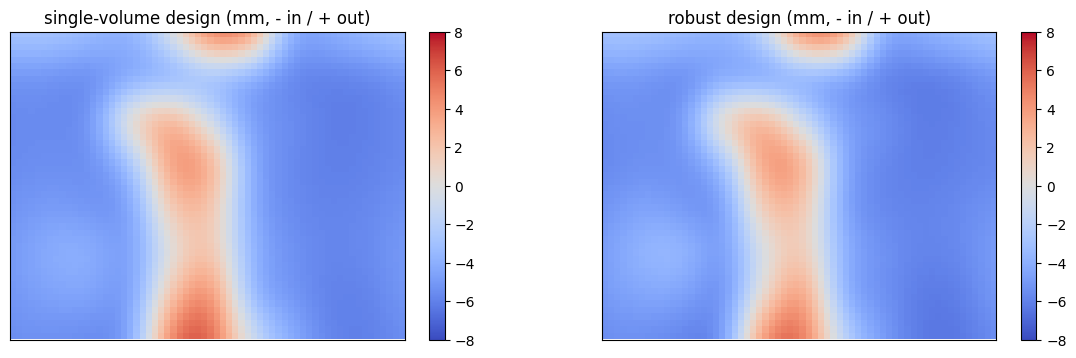

In [20]:
p = IDS['val'][:1]
designs = {'plain': torch.zeros(1, H, W, device=DEV), 'PTB': PTB[p],
           'single-volume': knobs_to_offset(K_SINGLE[p]), 'robust': knobs_to_offset(K_ROBUST[p])}
print(f'Patient {p[0]}   bony peak by volume: ' + '  '.join(f'{v:+.2%}' for v in VOLUME_CHANGES))
for name, off in designs.items():
    r = report(p, off)
    print(f'{name:14s} worst {r["worst"][0]:6.1f} kPa | ' + '  '.join(f'{x:6.1f}' for x in r['by_volume'][0]))

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axs, ['single-volume', 'robust']):
    im = ax.imshow(designs[name][0].cpu(), cmap='coolwarm', vmin=-8, vmax=8, aspect='auto')
    ax.set_title(f'{name} design (mm, - in / + out)'); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax)
plt.show()

## AI designer inputs from scan volume (0%)


In [15]:
allp = torch.arange(NP, device=DEV)
def limb_shift(s):
    return limb_at(allp, torch.full((NP,), REF, device=DEV), torch.full((NP,), s, device=DEV))

X = torch.stack([R_REF, limb_shift(15.0) - R_REF, limb_shift(30.0) - R_REF, T_[:, REF],
                 BONY.float(), PT.float(), torch.linspace(0, 1, H, device=DEV)[None, :, None].expand(NP, H, W)], 1)
X_MEAN = X[IDS['train']].mean((0, 2, 3), keepdim=True)
X_STD = X[IDS['train']].std((0, 2, 3), keepdim=True) + 1e-6
Xn = (X - X_MEAN) / X_STD
print('Designer input:', tuple(Xn.shape), '(patients, channels, height, angle)')

Designer input: (200, 7, 48, 64) (patients, channels, height, angle)


## Flip limb left to right for more data


In [16]:
def mirror(t):
    return torch.roll(torch.flip(t, [-1]), 1, -1)  # angle -> -angle on grid

R_REF, R_EXT, T_, BONY, PT, PTB = [torch.cat([a, mirror(a)]) for a in (R_REF, R_EXT, T_, BONY, PT, PTB)]
Z_, Z0, DZE = [torch.cat([a, a]) for a in (Z_, Z0, DZE)]
Xn = torch.cat([Xn, mirror(Xn)])
K_ROBUST_ALL = torch.cat([K_ROBUST, mirror(K_ROBUST)])
TRAIN_PLUS_MIRRORS = np.concatenate([IDS['train'], IDS['train'] + NP])

p = np.array([IDS['train'][0]])
a = report(p, knobs_to_offset(K_ROBUST_ALL[p]))['worst'][0]
b = report(p + NP, knobs_to_offset(K_ROBUST_ALL[p + NP]))['worst'][0]
print(f'Original limb + design: {a:.2f} kPa | mirrored limb + mirrored design: {b:.2f} kPa')
print('Training limbs with mirrors:', len(TRAIN_PLUS_MIRRORS))

Original limb + design: 2.84 kPa | mirrored limb + mirrored design: 2.84 kPa
Training limbs with mirrors: 280


## Designer network
Convolutional encoder and fully connected head


In [13]:
class EdgePad(nn.Module):
    def forward(self, x):
        return F.pad(F.pad(x, (1, 1, 0, 0), mode='circular'), (0, 0, 1, 1), mode='replicate')

def down_block(c_in, c_out):
    return nn.Sequential(EdgePad(), nn.Conv2d(c_in, c_out, 3), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

class SocketDesigner(nn.Module):
    def __init__(self, c_in=7, c=16):
        super().__init__()
        self.encoder = nn.Sequential(down_block(c_in, c), down_block(c, 2 * c), down_block(2 * c, 4 * c))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(4 * c * 6 * 8, 256), nn.ReLU(), nn.Dropout(0.3),
                                  nn.Linear(256, NK_Z * NK_TH))
        nn.init.zeros_(self.head[-1].weight); nn.init.zeros_(self.head[-1].bias)  # start = plain socket
    def forward(self, x):
        return to_knobs(self.head(self.encoder(x)).view(-1, NK_Z, NK_TH))

designer = SocketDesigner().to(DEV)
print(f'Weights to learn: {sum(q.numel() for q in designer.parameters()):,}')

def designer_says(p):
    designer.eval()
    with torch.no_grad():
        return designer(Xn[torch.as_tensor(p, device=DEV)])

Weights to learn: 831,632


## Training stage 1: learn from expert


epoch 100: train knob error 1.21 | val knob error 5.99
epoch 200: train knob error 0.95 | val knob error 6.17
epoch 300: train knob error 0.94 | val knob error 6.17
epoch 400: train knob error 0.95 | val knob error 6.05
epoch 500: train knob error 0.80 | val knob error 5.99
epoch 600: train knob error 0.82 | val knob error 6.02


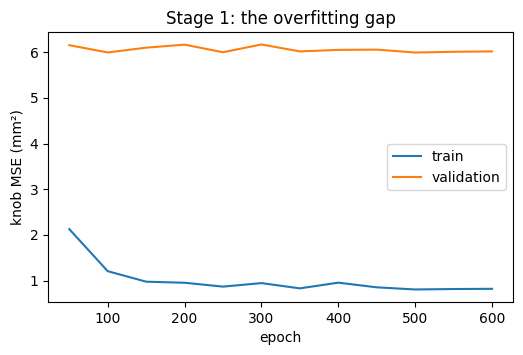

In [ ]:
TR = TRAIN_PLUS_MIRRORS
VAL_T = torch.as_tensor(IDS['val'], device=DEV)
EPOCHS_1 = 600
opt = torch.optim.Adam(designer.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_1)
curve = {'epoch': [], 'train': [], 'val': []}
for ep in range(EPOCHS_1):
    designer.train()
    for b in np.array_split(np.random.permutation(TR), 10):
        b = torch.as_tensor(b, device=DEV)
        loss = F.mse_loss(designer(Xn[b]), K_ROBUST_ALL[b])
        opt.zero_grad(); loss.backward(); opt.step()
    sched.step()
    if (ep + 1) % 50 == 0:
        val = F.mse_loss(designer_says(IDS['val']), K_ROBUST_ALL[VAL_T]).item()
        curve['epoch'].append(ep + 1); curve['train'].append(loss.item()); curve['val'].append(val)
        if (ep + 1) % 100 == 0:
            print(f'epoch {ep + 1}: train knob error {loss.item():.2f} | val knob error {val:.2f}')

plt.figure(figsize=(6, 3.5))
plt.plot(curve['epoch'], curve['train'], label='train'); plt.plot(curve['epoch'], curve['val'], label='validation')
plt.xlabel('epoch'); plt.ylabel('knob MSE (mm²)'); plt.title('Stage 1: the overfitting gap'); plt.legend(); plt.show()

## Training stage 2: learn from physics


In [ ]:
EPOCHS_2 = 40
opt = torch.optim.Adam(designer.parameters(), lr=3e-4, weight_decay=1e-4)
def val_score():
    return np.median(report(IDS['val'], knobs_to_offset(designer_says(IDS['val'])))['worst'])
best = val_score(); best_state = {k: v.clone() for k, v in designer.state_dict().items()}
print(f'start of stage 2: val median worst-of-day {best:.1f} kPa')
for ep in range(EPOCHS_2):
    designer.train()
    for b in np.array_split(np.random.permutation(TR), 10):
        loss = objective(b, designer(Xn[torch.as_tensor(b, device=DEV)])).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    score = val_score()
    if score < best:
        best, best_state = score, {k: v.clone() for k, v in designer.state_dict().items()}
    if (ep + 1) % 10 == 0:
        print(f'epoch {ep + 1}: val median worst-of-day {score:.1f} kPa (best {best:.1f})')
designer.load_state_dict(best_state)

start of stage 2: val median worst-of-day 25.8 kPa
epoch 10: val median worst-of-day 20.4 kPa (best 19.4)
epoch 20: val median worst-of-day 21.5 kPa (best 19.4)
epoch 30: val median worst-of-day 18.9 kPa (best 18.4)
epoch 40: val median worst-of-day 19.4 kPa (best 18.4)


<All keys matched successfully>

## Compare designs (used median)
- worst-of-day bony peak
- worst pressure anywhere
- deepest sink
- % patients where PTB is beaten


design                  worst bony  any peak   sink  beats PTB
plain                      80.3 kPa   87.6 kPa 18.2 mm       60%
PTB                        78.0 kPa   80.9 kPa 17.0 mm        0%
single-volume expert       19.1 kPa   34.5 kPa 13.2 mm      100%
AI instant                 22.7 kPa   35.9 kPa  9.4 mm       97%
robust expert              13.4 kPa   34.0 kPa 11.7 mm      100%


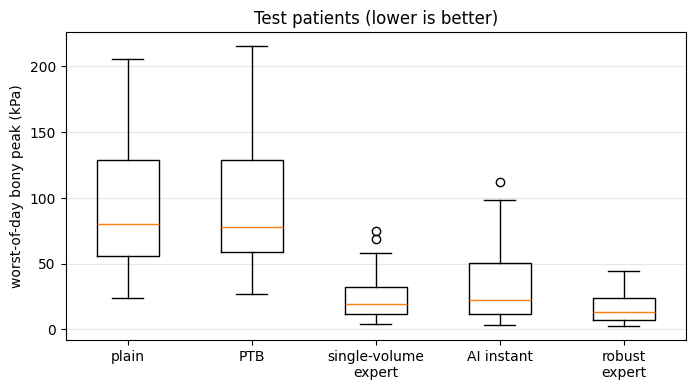

In [19]:
te = IDS['test']
test_designs = {'plain': torch.zeros(len(te), H, W, device=DEV), 'PTB': PTB[te],
                'single-volume expert': knobs_to_offset(K_SINGLE[te]),
                'AI instant': knobs_to_offset(designer_says(te)),
                'robust expert': knobs_to_offset(K_ROBUST[te])}
results = {name: report(te, off) for name, off in test_designs.items()}
ptb_worst = results['PTB']['worst']
print(f'{"design":22s} {"worst bony":>11s} {"any peak":>9s} {"sink":>6s} {"beats PTB":>10s}')
for name, r in results.items():
    print(f'{name:22s} {np.median(r["worst"]):8.1f} kPa {np.median(r["any_peak"]):6.1f} kPa {np.median(r["sink"]):4.1f} mm'
          f' {np.mean(r["worst"] < ptb_worst):9.0%}')

plt.figure(figsize=(8, 4))
plt.boxplot([r['worst'] for r in results.values()])
plt.xticks(range(1, len(results) + 1), [n.replace(' expert', '\nexpert') for n in results])
plt.ylabel('worst-of-day bony peak (kPa)'); plt.title('Test patients (lower is better)'); plt.grid(alpha=0.3, axis='y')
plt.show()

## AI draft + quick polish


steps | from plain socket | from AI draft     (median worst-of-day bony peak, kPa, test patients)
    0 |              80.3 |          22.7
   10 |              50.7 |          14.7
   25 |              34.1 |          11.5
   50 |              25.6 |          10.4
  100 |              18.2 |           9.4
  250 |              13.4 |           9.4


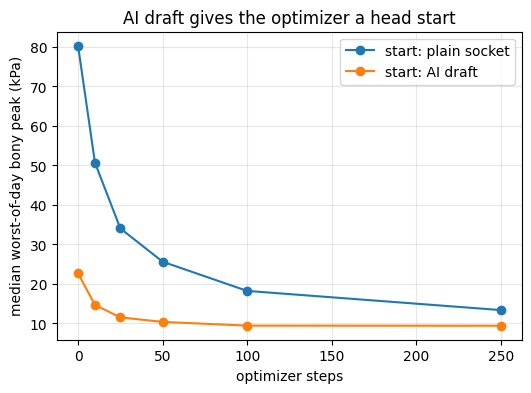

In [ ]:
CHECK = [0, 10, 25, 50, 100, 250]
_, from_plain = expert_optimize(te, steps=250, check_at=CHECK)
_, from_ai = expert_optimize(te, start=designer_says(te), steps=250, check_at=CHECK)
print('steps | from plain socket | from AI draft     (median worst-of-day bony peak, kPa, test patients)')
for s in CHECK:
    print(f'{s:5d} | {np.median(from_plain[s]):17.1f} | {np.median(from_ai[s]):13.1f}')

plt.figure(figsize=(6, 4))
plt.plot(CHECK, [np.median(from_plain[s]) for s in CHECK], 'o-', label='start: plain socket')
plt.plot(CHECK, [np.median(from_ai[s]) for s in CHECK], 'o-', label='start: AI draft')
plt.xlabel('optimizer steps'); plt.ylabel('median worst-of-day bony peak (kPa)')
plt.title('AI draft gives the optimizer a head start'); plt.legend(); plt.grid(alpha=0.3); plt.show()

## Speed analysis

In [ ]:
p1 = te[:1]
t0 = time.time(); _ = designer_says(p1)
if DEV == 'cuda': torch.cuda.synchronize()
t_ai = time.time() - t0
t0 = time.time(); _ = expert_optimize(p1, steps=250)
t_exp = time.time() - t0
t0 = time.time(); _ = expert_optimize(p1, start=designer_says(p1), steps=25)
t_mix = time.time() - t0
print(f'AI instant design:      {1000 * t_ai:7.1f} ms')
print(f'Expert, 250 steps:      {1000 * t_exp:7.1f} ms')
print(f'AI draft + 25 steps:    {1000 * t_mix:7.1f} ms')

AI instant design:         46.4 ms
Expert, 250 steps:       6644.4 ms
AI draft + 25 steps:      652.2 ms


## Save everything

In [ ]:
torch.save({'state_dict': designer.state_dict(), 'x_mean': X_MEAN.cpu(), 'x_std': X_STD.cpu(),
            'objective': dict(TAU=TAU, W_ANY=W_ANY, W_TIDY=W_TIDY), 'settings': G['settings']},
           f'{OUT_DIR}/designer_v1.pt')
np.savez(f'{OUT_DIR}/phase3_test_results.npz', **{k.replace(' ', '_'): v['worst'] for k, v in results.items()},
         test_ids=te, from_plain=np.array([from_plain[s] for s in CHECK]),
         from_ai=np.array([from_ai[s] for s in CHECK]), check_steps=np.array(CHECK))
print('Saved designer_v1.pt, expert_knobs_v1.npz, phase3_test_results.npz')

Saved designer_v1.pt, expert_knobs_v1.npz, phase3_test_results.npz
